# Food Delivery Orders Exploratory Data Analysis

## 1.Project Introduction
### Project Scenario
A food delivery company processes thousands of orders across multiple cities, restaurant types, and cuisines. The company wants to understand order patterns, customer preferences, delivery performance, and customer satisfaction.

As a **Data Analyst**, your task is to perform **Exploratory Data Analysis (EDA)** on historical food delivery data and identify useful business insights.

### Project Objectives
- Understand the structure and quality of the data.
- Identify and handle missing values, duplicates, inconsistent values, and outliers.
- Understand ordering and spending patterns.
- Identify popular cuisines and restaurant types.
- Analyze trends across cities and time periods.
- Evaluate delivery performance.
- Study relationships among distance, delivery time, and customer ratings.
- Generate business insights and recommendations.

### Dataset Description
The dataset contains about **5,000 food delivery orders**.

| Column | Description |
|---|---|
| `Order_ID` | Unique identifier for each order |
| `Order_Date` | Date on which the order was placed |
| `Order_Time` | Time at which the order was placed |
| `Customer_ID` | Unique customer identifier |
| `City` | City where the order was placed |
| `Restaurant_Type` | Type of restaurant |
| `Cuisine` | Type of cuisine ordered |
| `Order_Value` | Value of the food order |
| `Delivery_Fee` | Delivery charge |
| `Payment_Method` | Payment method used |
| `Delivery_Time_Min` | Delivery time in minutes |
| `Distance_KM` | Restaurant-to-customer distance |
| `Customer_Rating` | Rating given by the customer |
| `Order_Status` | Final status of the order |

### EDA Workflow
**Understand → Assess Quality → Clean → Create Features → Analyze → Visualize → Interpret → Recommend**

## 2. Import Libaries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Load the DataSet

In [2]:
df=pd.read_csv("food_delivery_orders_eda.csv")
df.head()

,Order_ID,Order_Date,Order_Time,Customer_ID,City,Restaurant_Type,Cuisine,Order_Value,Delivery_Fee,Payment_Method,Delivery_Time_Min,Distance_KM,Customer_Rating,Order_Status
0,ORD103631,16-11-2025,22:42:30,C1467,Bangalore,Cloud Kitchen,Desserts,172.11,46.40,UPI,31.2,2.9,5.0,Delivered
1,ORD100840,08-09-2025,14:56:00,C1205,Bangalore,Cafe,Desserts,90.00,39.64,UPI,31.6,3.2,4.6,Delivered
2,ORD103690,26-01-2025,20:52:15,C1084,Chennai,Cafe,Biryani,299.69,45.51,Wallet,33.6,2.9,4.8,Delivered
3,ORD104690,21-02-2025,14:37:30,C1799,Kochi,Fast Food,Biryani,247.32,32.94,Debit Card,29.8,2.2,4.5,Delivered
4,ORD101595,12-02-2025,17:27:00,C1596,Hyderabad,Fast Food,South Indian,218.73,49.14,UPI,29.1,3.9,5.0,Delivered


## 4.Understanding the Dataset

### Display First 3 Rows

In [3]:
df.head(3)

,Order_ID,Order_Date,Order_Time,Customer_ID,City,Restaurant_Type,Cuisine,Order_Value,Delivery_Fee,Payment_Method,Delivery_Time_Min,Distance_KM,Customer_Rating,Order_Status
0,ORD103631,16-11-2025,22:42:30,C1467,Bangalore,Cloud Kitchen,Desserts,172.11,46.40,UPI,31.2,2.9,5.0,Delivered
1,ORD100840,08-09-2025,14:56:00,C1205,Bangalore,Cafe,Desserts,90.00,39.64,UPI,31.6,3.2,4.6,Delivered
2,ORD103690,26-01-2025,20:52:15,C1084,Chennai,Cafe,Biryani,299.69,45.51,Wallet,33.6,2.9,4.8,Delivered


### Check Number of Rows and Columns

In [4]:
df.shape

(5000, 14)

### View Column Name

In [5]:
df.columns

Index(['Order_ID', 'Order_Date', 'Order_Time', 'Customer_ID', 'City',
       'Restaurant_Type', 'Cuisine', 'Order_Value', 'Delivery_Fee',
       'Payment_Method', 'Delivery_Time_Min', 'Distance_KM', 'Customer_Rating',
       'Order_Status'],
      dtype='str')

### Check Datatype and Non-Null Values

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           5000 non-null   str    
 1   Order_Date         5000 non-null   str    
 2   Order_Time         5000 non-null   str    
 3   Customer_ID        5000 non-null   str    
 4   City               5000 non-null   str    
 5   Restaurant_Type    5000 non-null   str    
 6   Cuisine            4958 non-null   str    
 7   Order_Value        5000 non-null   float64
 8   Delivery_Fee       5000 non-null   float64
 9   Payment_Method     5000 non-null   str    
 10  Delivery_Time_Min  4677 non-null   float64
 11  Distance_KM        5000 non-null   float64
 12  Customer_Rating    4611 non-null   float64
 13  Order_Status       5000 non-null   str    
dtypes: float64(5), str(9)
memory usage: 547.0 KB


### Statistical Summary

In [7]:
df.describe()

,Order_Value,Delivery_Fee,Delivery_Time_Min,Distance_KM,Customer_Rating
count,5000.000000,5000.000000,4677.000000,5000.00000,4611.000000
mean,430.642108,40.056242,35.265640,4.25742,4.427239
std,332.477755,15.788187,12.363382,2.54374,0.399109
min,90.000000,0.000000,12.000000,0.50000,2.700000
25%,267.267500,29.347500,27.200000,2.40000,4.200000
50%,372.580000,38.605000,34.300000,3.70000,4.500000
75%,513.367500,49.467500,42.000000,5.60000,4.700000
max,7777.620000,110.540000,172.100000,15.00000,5.000000


### Initial Observations

This dataset contains 5000 Rows and 14 Columns.
The Numerical columns are Order_value,Delivery_fee,Delivery_time_min,Distance_KM,Customer_Rating.
The Categorical columns are City,Restaurant_Type,Cuisine,Payment_Method,Order_Status.
Cuisine,Delivery_time_min,Customer_Rating These columns contains messing values.

## 5. Data Quality Assessment

### Check missing values

In [8]:
df.isnull().sum()

Order_ID               0
Order_Date             0
Order_Time             0
Customer_ID            0
City                   0
Restaurant_Type        0
Cuisine               42
Order_Value            0
Delivery_Fee           0
Payment_Method         0
Delivery_Time_Min    323
Distance_KM            0
Customer_Rating      389
Order_Status           0
dtype: int64

### Missing value Percentage


In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage

Order_ID             0.00
Order_Date           0.00
Order_Time           0.00
Customer_ID          0.00
City                 0.00
Restaurant_Type      0.00
Cuisine              0.84
Order_Value          0.00
Delivery_Fee         0.00
Payment_Method       0.00
Delivery_Time_Min    6.46
Distance_KM          0.00
Customer_Rating      7.78
Order_Status         0.00
dtype: float64

### Check Duplicate Rows

In [10]:
df.duplicated().sum()

np.int64(12)

### Inspect Categorical Values

In [11]:
categorical_columns = ["City", "Restaurant_Type", "Cuisine", "Payment_Method", "Order_Status"]

for column in categorical_columns:
    print("\n")
    print(df[column].value_counts(dropna=False))



City
Bangalore      1524
Mumbai         1048
Hyderabad      1006
Chennai         867
Kochi           543
 Bangalore        5
 Mumbai           3
 Hyderabad        2
 Chennai          1
 Kochi            1
Name: count, dtype: int64


Restaurant_Type
Fast Food        1432
Cloud Kitchen    1198
Casual Dining    1194
Cafe              792
Fine Dining       384
Name: count, dtype: int64


Cuisine
North Indian    910
South Indian    884
Biryani         858
Chinese         722
Fast Food       554
Italian         405
Desserts        360
Continental     265
NaN              42
Name: count, dtype: int64


Payment_Method
UPI            2206
Credit Card     917
Cash            868
Debit Card      572
Wallet          429
upi               7
Upi               1
Name: count, dtype: int64


Order_Status
Delivered    4620
Cancelled     287
Refunded       93
Name: count, dtype: int64


### Obeservation 

Cuisine has 42 missing value.<br>
Delivery_Time_Min has 323 missing value.<br>
Customer_Rating has 389 missing value.<br>
There are 12 duplicate rows in the Dataset. <br>
There are capitalization and white space issues in City and Payment method columns.<br>


## 6.Data Cleaning

### Remove Duplicate Records

In [12]:
df=df.drop_duplicates()

In [13]:
df.shape

(4988, 14)

### Remove Extra Space from Text Column

In [14]:
text_columns = ["City", "Restaurant_Type", "Cuisine", "Payment_Method", "Order_Status"]

for column in text_columns:
    df[column] = df[column].str.strip()

In [15]:
df["City"].value_counts()

City
Bangalore    1525
Mumbai       1047
Hyderabad    1005
Chennai       868
Kochi         543
Name: count, dtype: int64

### Handle capitalization issuse in payment method column

In [16]:
df["Payment_Method"]=df["Payment_Method"].replace("upi","UPI")

In [17]:
df["Payment_Method"]=df["Payment_Method"].replace("Upi","UPI")

In [18]:
df["Payment_Method"].value_counts()

Payment_Method
UPI            2208
Credit Card     915
Cash            866
Debit Card      571
Wallet          428
Name: count, dtype: int64

### Handle the missing cuisine values

In [19]:
df["Cuisine"]=df["Cuisine"].fillna("Unkown")

In [20]:
df["Cuisine"].isnull().sum()

np.int64(0)

### Handle the missing delivery time and Customer rating

In [21]:
df[df["Delivery_Time_Min"].isnull()]["Order_Status"].value_counts()

Order_Status
Cancelled    286
Delivered     36
Name: count, dtype: int64

In [22]:
delivery_median=df["Delivery_Time_Min"].median()

In [23]:
df.loc[(df["Order_Status"] == "Delivered") & (df["Delivery_Time_Min"].isnull()), "Delivery_Time_Min"] = delivery_median

In [24]:
df.info()

<class 'pandas.DataFrame'>
Index: 4988 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           4988 non-null   str    
 1   Order_Date         4988 non-null   str    
 2   Order_Time         4988 non-null   str    
 3   Customer_ID        4988 non-null   str    
 4   City               4988 non-null   str    
 5   Restaurant_Type    4988 non-null   str    
 6   Cuisine            4988 non-null   str    
 7   Order_Value        4988 non-null   float64
 8   Delivery_Fee       4988 non-null   float64
 9   Payment_Method     4988 non-null   str    
 10  Delivery_Time_Min  4702 non-null   float64
 11  Distance_KM        4988 non-null   float64
 12  Customer_Rating    4600 non-null   float64
 13  Order_Status       4988 non-null   str    
dtypes: float64(5), str(9)
memory usage: 584.5 KB


In [25]:
df.isnull().sum()

Order_ID               0
Order_Date             0
Order_Time             0
Customer_ID            0
City                   0
Restaurant_Type        0
Cuisine                0
Order_Value            0
Delivery_Fee           0
Payment_Method         0
Delivery_Time_Min    286
Distance_KM            0
Customer_Rating      388
Order_Status           0
dtype: int64

## 7.Feature Engineering

In [26]:
df["Order_Date"]=pd.to_datetime(df["Order_Date"])

C:\Users\NITIN HULLUR\AppData\Local\Temp\ipykernel_3996\544640231.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Order_Date"]=pd.to_datetime(df["Order_Date"])


In [27]:
df["Order_Date"].dtype

dtype('<M8[us]')

### Create a month column

In [28]:
df["Month"]=df["Order_Date"].dt.month_name()

In [29]:
df["Month"].head(1)

0    November
Name: Month, dtype: str

### Create a Day

In [30]:
df["Day"]=df["Order_Date"].dt.day_name()

In [31]:
df["Day"].head()

0       Sunday
1       Monday
2       Sunday
3       Friday
4    Wednesday
Name: Day, dtype: str

### Extract order hours

In [32]:
df["Order_Time"]=pd.to_datetime(df["Order_Time"])

C:\Users\NITIN HULLUR\AppData\Local\Temp\ipykernel_3996\21909411.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Order_Time"]=pd.to_datetime(df["Order_Time"])


In [33]:
df["Order_Hour"]=df["Order_Time"].dt.hour

In [34]:
df["Order_Hour"].head()

0    22
1    14
2    20
3    14
4    17
Name: Order_Hour, dtype: int32

### Create Order Period

In [35]:
def order_period(hour):
    if 6 <= hour < 11:
        return "Morning"
    elif 11 <= hour < 15:
        return "Lunch"
    elif 15 <= hour < 18:
        return "Afternoon"
    elif 18 <= hour < 23:
        return "Dinner"
    else:
        return "Late Night"

df["Order_Period"] = df["Order_Hour"].apply(order_period)
df["Order_Period"].value_counts()

Order_Period
Dinner        2253
Lunch         1442
Afternoon      657
Morning        368
Late Night     268
Name: count, dtype: int64

In [36]:
df["Order_Period"].head()

0       Dinner
1        Lunch
2       Dinner
3        Lunch
4    Afternoon
Name: Order_Period, dtype: str

## 8.Univeriate Analysis

### Distribution of Order Values

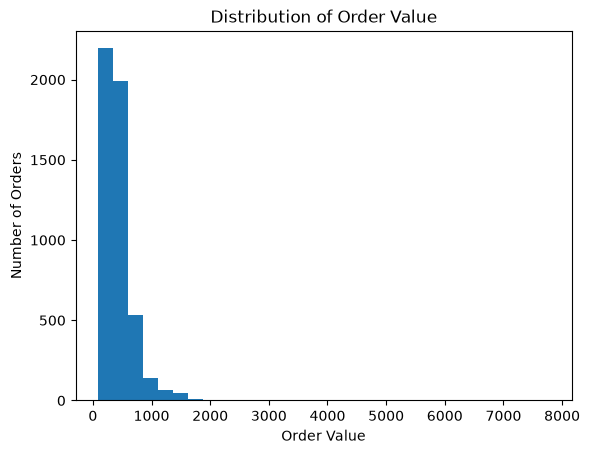

In [37]:
plt.hist(df["Order_Value"], bins=30)
plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")
plt.show()

**Observation.**<br>
Most orders primarly below thousand.<br>
Number of order decrease when the order value increase.<br>


### Distribution delivery time 

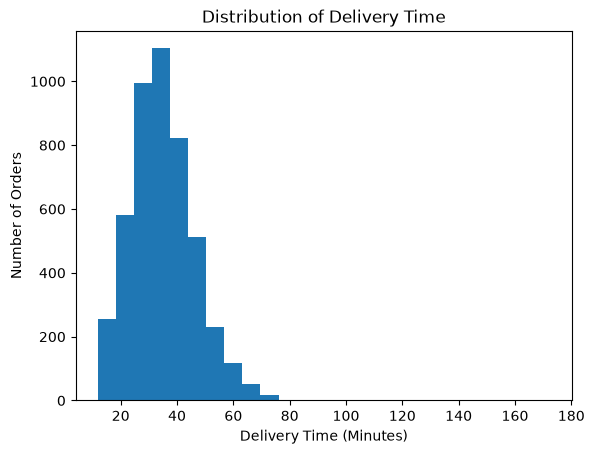

In [38]:
plt.hist(df["Delivery_Time_Min"].dropna(), bins=25)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Number of Orders")
plt.show()

**Observation.**<br>
Most of orders are deliveryed in 20 to 50 mintues.<br>
The Highest number of orders are between 30 and 40 mintues.<br>

### Distribution of Cuatomer Rating

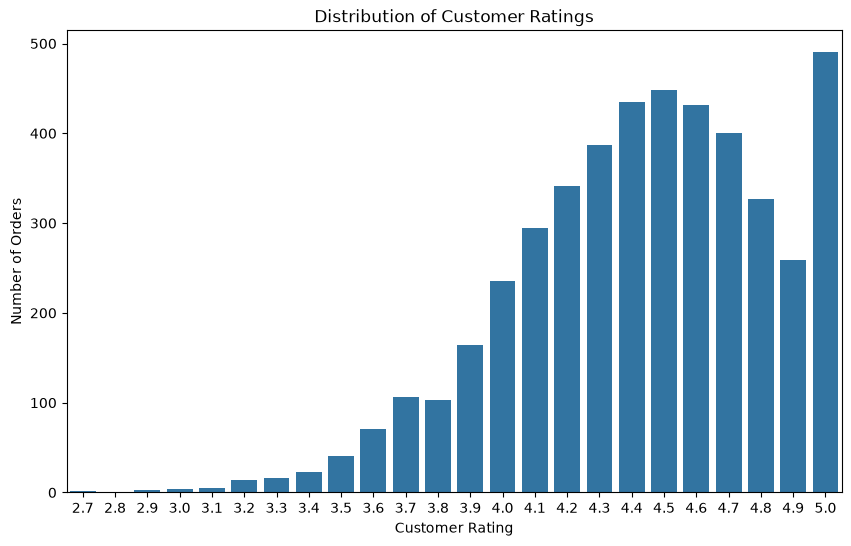

In [39]:
plt.figure(figsize=(10,6))
sns.countplot(data=df, x="Customer_Rating")
plt.title("Distribution of Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Orders")
plt.show()

**Observation.**<br>
Most of the Customer gave "5.0" rating.<br>
A lot orders got rating between 4 to 4.9.<br>
Very less orders got below 3.8 rating.<br>

### Orders by City

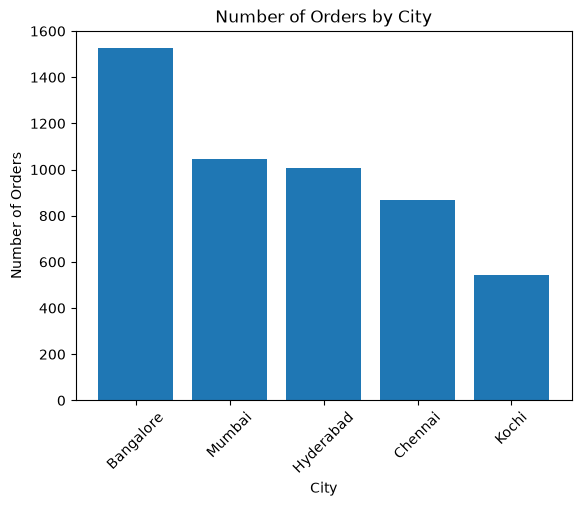

In [40]:
city_orders = df["City"].value_counts()

plt.bar(city_orders.index, city_orders.values)

plt.title("Number of Orders by City")
plt.xlabel("City")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

**Observation.**<br>
Bangalore has the highest no.of order with 1525.<br>
Followed by Mumbai with 1047 orders and <br>
Kochi has least orders with 543 numbers.

### Order by cuisine

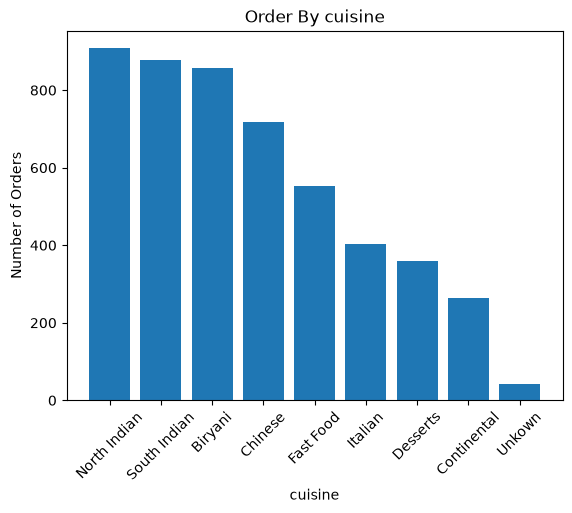

In [41]:
cuisine_count = df["Cuisine"].value_counts()

plt.bar(cuisine_count.index, cuisine_count.values)

plt.title("Order By cuisine")
plt.xlabel("cuisine")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

**Observation.**<br>
North Indian,south Indian and Biryani has above 800 number of orders.<br>
Italian,Desserts,Continental has less orders with less than 400 orders.<br>


### Orders by Restaurant_Type type

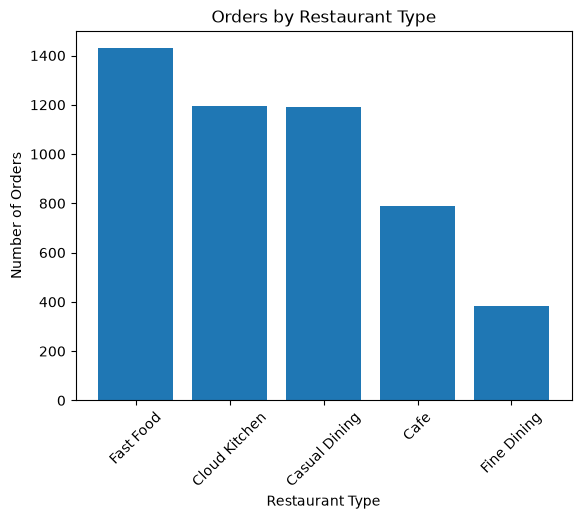

In [42]:
restaurant_counts = df["Restaurant_Type"].value_counts()

plt.bar(restaurant_counts.index, restaurant_counts.values)

plt.title("Orders by Restaurant Type")
plt.xlabel("Restaurant Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

**Observation.**<br>
Fast food has the highest no.of orders above the 1400 order numbers.<br>
fine dining is the least order in the data set.

### orders by payment method

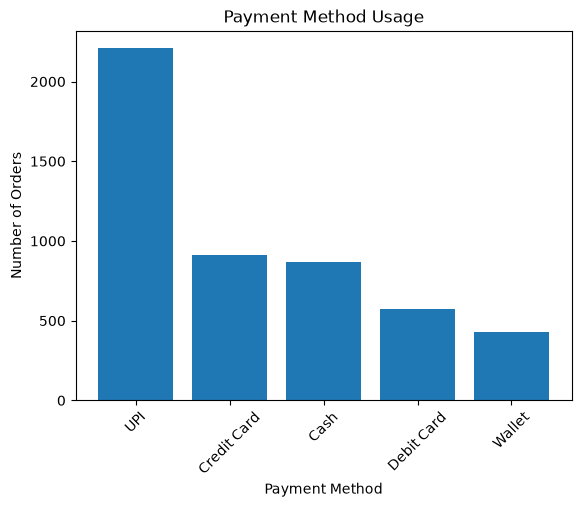

In [43]:
payment_counts = df["Payment_Method"].value_counts()

plt.bar(payment_counts.index, payment_counts.values)

plt.title("Payment Method Usage")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

**Observation.**<br> 
UPI  is used highest payment method.<br>
wallet is used least time to do payment.

### Order Status Distrubation 


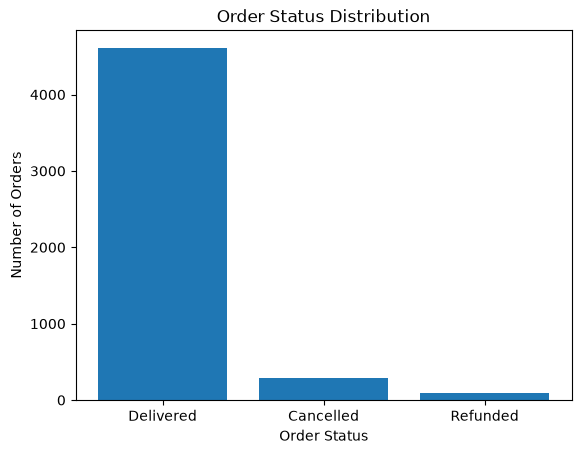

In [44]:
status_counts = df["Order_Status"].value_counts()

plt.bar(status_counts.index, status_counts.values)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.show()

**Observation.**<br>
Here most orders are delivered.
  

## 9. Outlier Analysis

### Box plot of Order Value

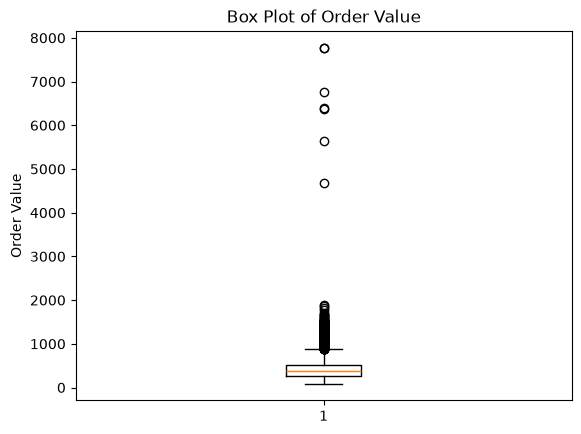

In [45]:
plt.boxplot(df["Order_Value"].dropna())
plt.title("Box Plot of Order Value")
plt.ylabel("Order Value")
plt.show()

**Outlier Observation<br>**
There are multiple outliers in order value column,but since the dataset is regarding food delivery it is possible to have larger order values.

### Calculate the IQR 

In [46]:
Q1 = df["Order_Value"].quantile(0.25)
Q3 = df["Order_Value"].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Fence:", lower_fence)
print("Upper Fence:", upper_fence)

Q1: 267.3175
Q3: 513.7874999999999
IQR: 246.4699999999999
Lower Fence: -102.38749999999987
Upper Fence: 883.4924999999998


In [47]:
order_value_outliers = df[(df["Order_Value"] < lower_fence) | (df["Order_Value"] > upper_fence)]
order_value_outliers

,Order_ID,Order_Date,Order_Time,Customer_ID,City,Restaurant_Type,Cuisine,Order_Value,Delivery_Fee,Payment_Method,Delivery_Time_Min,Distance_KM,Customer_Rating,Order_Status,Month,Day,Order_Hour,Order_Period
36,ORD100361,2025-12-05,2026-10-27 22:21:30,C2120,Bangalore,Fine Dining,Continental,1105.69,25.26,Cash,35.2,3.9,4.9,Delivered,December,Friday,22,Dinner
41,ORD100734,2025-01-27,2026-10-27 20:28:15,C1692,Bangalore,Fine Dining,Biryani,1397.67,11.98,Credit Card,40.9,4.7,4.3,Delivered,January,Monday,20,Dinner
47,ORD100704,2025-09-17,2026-10-27 18:51:30,C1467,Mumbai,Fine Dining,Biryani,1373.77,13.65,Credit Card,25.2,4.0,4.3,Refunded,September,Wednesday,18,Dinner
113,ORD103655,2025-10-04,2026-10-27 20:59:45,C1328,Hyderabad,Fine Dining,South Indian,1188.58,31.35,Cash,51.7,5.6,3.5,Delivered,October,Saturday,20,Dinner
117,ORD104234,2025-02-21,2026-10-27 12:26:45,C1291,Bangalore,Fine Dining,Italian,1377.29,0.92,Cash,27.4,1.8,5.0,Delivered,February,Friday,12,Lunch
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4916,ORD102229,2025-03-15,2026-10-27 22:56:30,C2020,Bangalore,Fine Dining,Biryani,1541.60,0.00,UPI,NaN,2.0,NaN,Cancelled,March,Saturday,22,Dinner
4930,ORD101118,2025-10-02,2026-10-27 14:50:30,C1863,Bangalore,Casual Dining,Continental,940.82,20.47,Cash,19.0,2.7,4.9,Delivered,October,Thursday,14,Lunch
4935,ORD104014,2025-10-25,2026-10-27 11:00:00,C1008,Kochi,Casual Dining,Italian,886.55,20.67,Cash,NaN,4.1,NaN,Cancelled,October,Saturday,11,Lunch
4942,ORD103445,2025-12-25,2026-10-27 11:06:00,C1828,Mumbai,Casual Dining,Italian,909.12,32.57,UPI,35.0,8.1,4.8,Delivered,December,Thursday,11,Lunch


## 10. Time Based Analysis

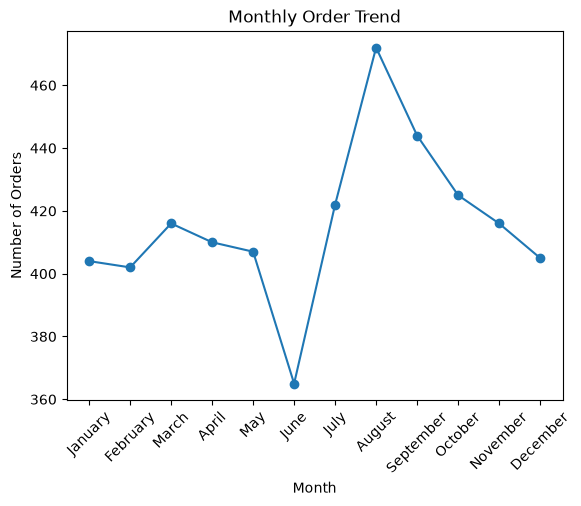

In [48]:
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
monthly_orders = df["Month"].value_counts().reindex(month_order)

plt.plot(monthly_orders.index, monthly_orders.values, marker="o")
plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

**Observation.**<br>
June has least No.of orders.<br>
August has the highest no.of orders.

##  Orders by day of Week 

In [49]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
day_order = df["Day"].value_counts().reindex(weekday_order)
day_order

Day
Monday       656
Tuesday      695
Wednesday    696
Thursday     747
Friday       661
Saturday     752
Sunday       781
Name: count, dtype: int64

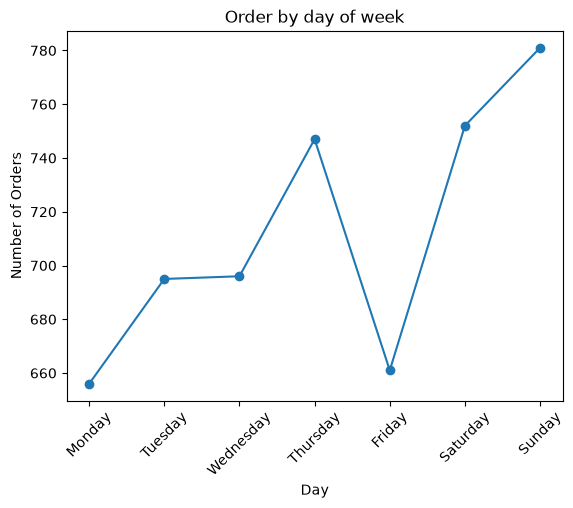

In [50]:
plt.plot(day_order.index,day_order.values,marker="o")
plt.title("Order by day of week")
plt.xlabel("Day")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.show()

**Observation.**<br>
Monday and Friday has the less order.<br>
Saturday and Sunday has the highest order.

## Order by Hours

In [51]:
hourly_orders = df["Order_Hour"].value_counts().sort_index()
hourly_orders

Order_Hour
0      16
1      17
2      16
3      21
4      16
5      24
6      22
7      92
8      79
9      91
10     84
11    350
12    344
13    362
14    386
15    228
16    210
17    219
18    451
19    461
20    437
21    461
22    443
23    158
Name: count, dtype: int64

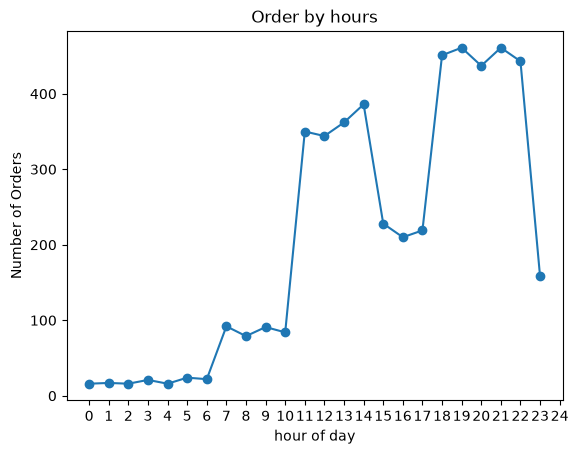

In [52]:
plt.plot(hourly_orders.index,hourly_orders.values,marker="o")
plt.title("Order by hours")
plt.xlabel("hour of day")
plt.ylabel("Number of Orders")
plt.xticks(range(0,25))
plt.show()

**Observation.**<br>
11 am to 2 pm, and 6 pm to 10 pm the number of orders are very high.<br>
Between 11 pm to 6 am has the lesser number of orders.

## Orders by time Period

In [53]:
period_count = df["Order_Period"].value_counts().reindex(["Morning" ,"Lunch" ,"Afternoon","Dinner","Late Night"])
period_count

Order_Period
Morning        368
Lunch         1442
Afternoon      657
Dinner        2253
Late Night     268
Name: count, dtype: int64

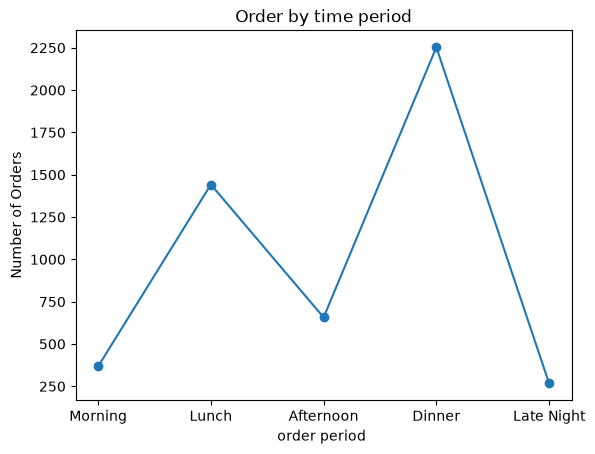

In [54]:
plt.plot(period_count.index,period_count.values,marker="o")
plt.title("Order by time period")
plt.xlabel("order period ")
plt.ylabel("Number of Orders")
plt.show()

**Observation.**<br>
Dinner has the highest number of orders.<br>
Morning and Late night has the lowest number of orders.

# 11 . Bivariate Analysis

## Distance vs Delivery Time

In [55]:
df.columns

Index(['Order_ID', 'Order_Date', 'Order_Time', 'Customer_ID', 'City',
       'Restaurant_Type', 'Cuisine', 'Order_Value', 'Delivery_Fee',
       'Payment_Method', 'Delivery_Time_Min', 'Distance_KM', 'Customer_Rating',
       'Order_Status', 'Month', 'Day', 'Order_Hour', 'Order_Period'],
      dtype='str')

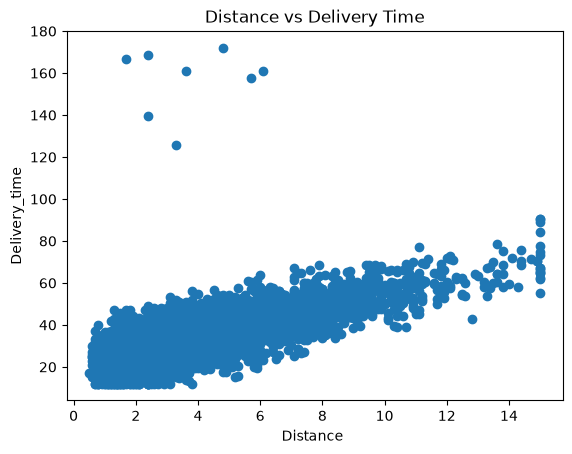

In [56]:
plt.scatter(df["Distance_KM"],df["Delivery_Time_Min"])
plt.title("Distance vs Delivery Time")
plt.xlabel("Distance ")
plt.ylabel("Delivery_time")
plt.show()

**Obersvation**<br>
When Distance increase delivery time also increases.<br>
distance and delivery time has a positive relationship

## Delivery time vs Customer Ratings

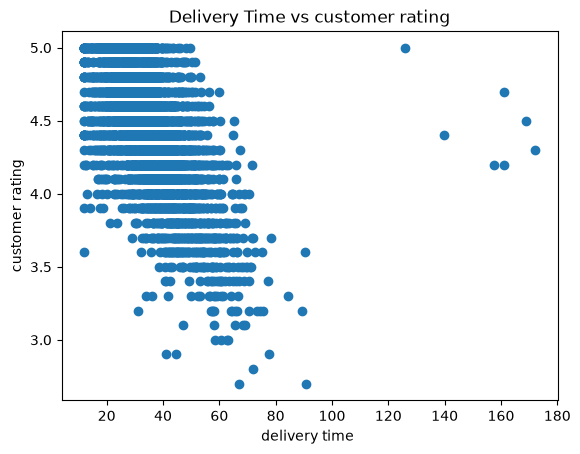

In [57]:
plt.scatter(df["Delivery_Time_Min"],df["Customer_Rating"])
plt.title("Delivery Time vs customer rating")
plt.xlabel("delivery time ")
plt.ylabel("customer rating")
plt.show()

**observation**<br>
when delivery time incerses customer rating decreseas.<br>
delivery time and customer rating has negative relationship.

## Correlation Analysis

In [58]:
df.columns

Index(['Order_ID', 'Order_Date', 'Order_Time', 'Customer_ID', 'City',
       'Restaurant_Type', 'Cuisine', 'Order_Value', 'Delivery_Fee',
       'Payment_Method', 'Delivery_Time_Min', 'Distance_KM', 'Customer_Rating',
       'Order_Status', 'Month', 'Day', 'Order_Hour', 'Order_Period'],
      dtype='str')

In [59]:
numeric_columns = ["Order_Value","Delivery_Fee","Delivery_Time_Min","Distance_KM","Customer_Rating"]
correlation_matrix = df[numeric_columns].corr()
correlation_matrix 


,Order_Value,Delivery_Fee,Delivery_Time_Min,Distance_KM,Customer_Rating
Order_Value,1.000000,-0.165873,0.011584,0.004889,-0.007262
Delivery_Fee,-0.165873,1.000000,0.559486,0.804421,-0.410506
Delivery_Time_Min,0.011584,0.559486,1.000000,0.693296,-0.580728
Distance_KM,0.004889,0.804421,0.693296,1.000000,-0.506625
Customer_Rating,-0.007262,-0.410506,-0.580728,-0.506625,1.000000


## Correlation HeatMap

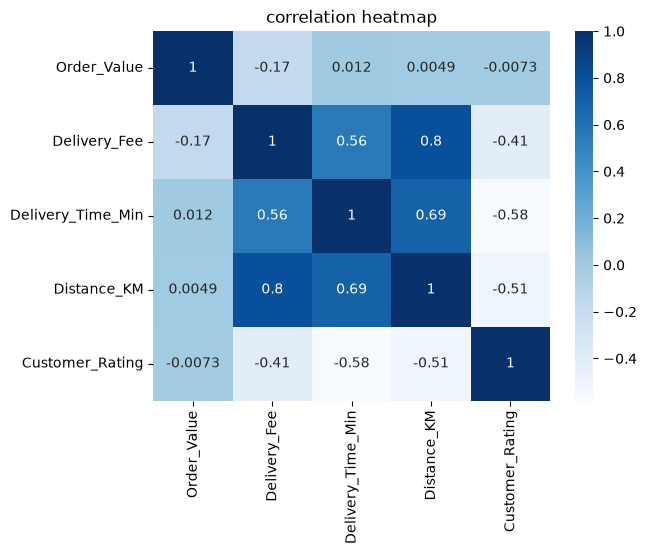

In [60]:
sns.heatmap(correlation_matrix , cmap="Blues",annot=True)
plt.title("correlation heatmap")
plt.show()

**Observation**<br>
Delivery distance has a strong positive correlation with delivery fee (0.80) and delivery time (0.69).<br> Delivery time has a moderate negative correlation with customer rating (-0.58), suggesting that longer deliveries are associated with lower customer satisfaction.<br> Order value shows almost no correlation with delivery time, distance, or customer rating.

## Key Insights

### 1. Order Volume and Location

- After removing duplicate records, the dataset contains **4,988 unique orders**.
- **Bangalore recorded the highest number of orders (1,525)**, followed by Mumbai and Hyderabad.
- **Kochi recorded the lowest number of orders (543)**.
- Bangalore therefore represents the largest market in this dataset in terms of order volume.

### 2. Cuisine Preferences

- **North Indian cuisine was the most frequently ordered**, followed closely by South Indian and Biryani.
- Chinese and Fast Food also accounted for a considerable number of orders.
- Continental cuisine had comparatively lower demand.
- This indicates that Indian cuisines dominate customer preferences in the available order data.

### 3. Restaurant Type

- **Fast Food restaurants received the highest number of orders**, followed by Cloud Kitchens and Casual Dining restaurants.
- Fine Dining restaurants received the fewest orders.
- However, Fine Dining had a significantly higher **average order value of approximately ₹924**, compared with the other restaurant categories.
- This shows an important distinction between **order volume and order value**: a category receiving fewer orders can still generate high-value transactions.

### 4. Payment Preferences

- **UPI was the most commonly used payment method**, accounting for substantially more orders than any other payment option.
- Credit Card and Cash were the next most frequently used methods.
- Wallet was the least frequently used payment method.
- The analysis therefore shows a strong customer preference for digital payments, particularly UPI.

### 5. Order Timing

- Order activity was noticeably higher during **lunch and dinner hours**.
- The strongest concentration of orders occurred during the evening, particularly around **6 PM to 10 PM**.
- **7 PM and 9 PM recorded some of the highest hourly order volumes**.
- This suggests that dinner is a particularly important operating period for the business.

### 6. Weekly Ordering Pattern

- **Sunday recorded the highest number of orders**, followed by Saturday.
- Weekend demand was therefore noticeably strong.
- However, total weekday and weekend counts should not be directly compared without considering that there are five weekdays but only two weekend days.
- Average daily order volume provides a more appropriate comparison when evaluating weekday versus weekend demand.

### 7. Order Completion

- Approximately **92.4% of orders were successfully delivered**.
- Around **5.7% were cancelled**, while approximately **1.9% were refunded**.
- The majority of transactions therefore reached successful delivery, although cancelled and refunded orders still represent an area that can be investigated further.

### 8. Delivery Performance

- Average delivery time varied across cities.
- **Mumbai had the highest average delivery time at approximately 37 minutes**, closely followed by Bangalore.
- **Kochi had the lowest average delivery time at approximately 32 minutes**.
- The differences suggest that delivery performance may vary depending on location and operating conditions.

### 9. Distance and Delivery Time

- A clear positive relationship was observed between **delivery distance and delivery time**.
- The correlation between the two variables was approximately **0.69**.
- Longer-distance orders therefore generally required more time to deliver.
- However, the relationship was not perfect, indicating that factors other than distance also influence delivery time.

### 10. Delivery Distance and Delivery Fee

- Delivery distance showed a strong positive relationship with **delivery fee**, with a correlation of approximately **0.80**.
- This indicates that longer-distance orders generally attract higher delivery charges.
- Order value showed a slight negative relationship with delivery fee, which is consistent with some higher-value orders receiving reduced delivery charges.

### 11. Delivery Performance and Customer Satisfaction

- Delivery time showed a moderate negative relationship with **customer rating**, with a correlation of approximately **-0.58**.
- This means that as delivery time increases, customer ratings generally tend to decrease.
- Distance also had a negative relationship with ratings, which may partly occur because longer distances tend to result in longer delivery times.
- Delivery speed therefore appears to be an important factor associated with customer satisfaction.

### 12. Restaurant Type and Ratings

- Average customer ratings were relatively similar across restaurant types.
- No restaurant category showed an exceptionally large advantage in customer ratings.
- This suggests that restaurant type alone may not be a major factor determining customer satisfaction in this dataset.

## Business Recomendations

- Increase Delivery Capacity During Peak Hours
- Strengthen Weekend Operations
- Focus on High-Demand Cuisines
- Treat Fine Dining as a High-Value Segment
- Improve Delivery Performance in Slower Cities
- Pay Particular Attention to Long-Distance Orders
- Reduce Delivery Delays to Improve Customer Satisfaction
- Investigate Cancelled and Refunded Orders
- Maintain a Smooth UPI Payment Experience

# Conclusion

This project demonstrates a complete Exploratory Data Analysis workflow using Python. It covers data understanding, cleaning, feature engineering, univariate and bivariate analysis, outlier detection, correlation, visualization, insight generation, and business recommendations.